# Predicting Ames Home Prices: Decision Tree vs. Random Forest vs. XGBoost

This notebook downloads the **Ames, Iowa housing dataset** (Dean De Cock, 2011 — the version used in Kaggle's *House Prices* competition, 1,460 homes × 80 features) and compares three tree-based regressors:

| Model | Idea |
|---|---|
| **Decision Tree** | A single tree of if/else splits — simple and interpretable, but prone to overfitting |
| **Random Forest** | Many deep trees trained on bootstrap samples, averaged (bagging) to reduce variance |
| **XGBoost** | Shallow trees added sequentially, each correcting the previous ones' errors (gradient boosting) |

**Comparison design** — every model gets the *same* data split, preprocessing, and evaluation:
1. Baseline models with default-ish settings, scored by 5-fold cross-validation
2. Hyperparameter tuning with the same search budget for each model
3. Final evaluation on a held-out test set (never touched during tuning)
4. Side-by-side metrics, training time, prediction plots, residuals, and feature importances

In [1]:
# Uncomment if any packages are missing
#%pip install -q scikit-learn xgboost pandas numpy matplotlib seaborn

# Mac users, if you get an error about 32bit vs 64bit, run the following command in your terminal to install libomp,
# install homebrew. Then, run the following command in your terminal to install libomp:
#%run brew install libomp

In [2]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, KFold, cross_validate, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from scipy.stats import randint, uniform, loguniform

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## 1. Download the data

In [3]:
# Downloads from OpenML (cached locally after the first run in ~/scikit_learn_data)
ames = fetch_openml(name="house_prices", version=1, as_frame=True, parser="auto")
df = ames.frame.copy()

print(f"Shape: {df.shape}")
df.head()

Shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,...,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,...,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,...,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,...,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,'Wd Sdng','Wd Shng',...,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,...,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 2. Quick exploration

count      1,460
mean     180,921
std       79,443
min       34,900
25%      129,975
50%      163,000
75%      214,000
max      755,000
Name: SalePrice, dtype: str


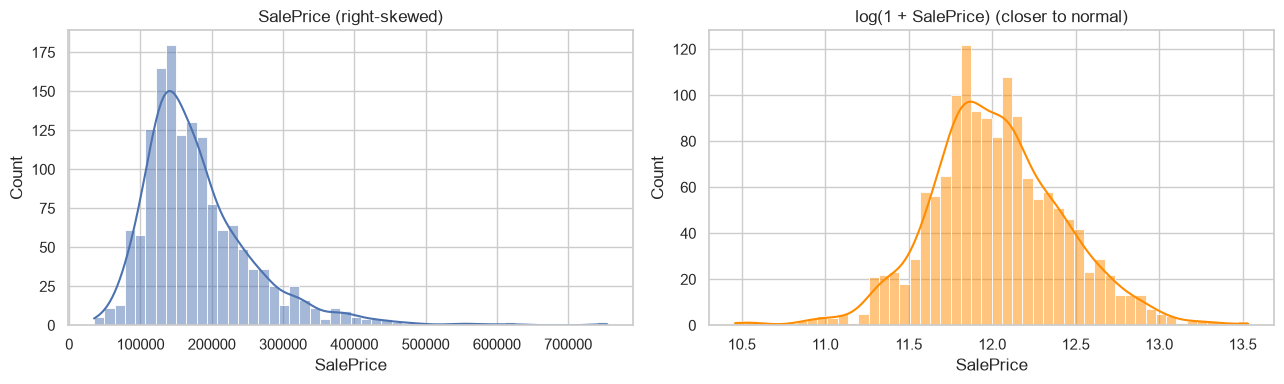

In [4]:
TARGET = "SalePrice"
df[TARGET] = df[TARGET].astype(float)
df = df.drop(columns=["Id"], errors="ignore")

print(df[TARGET].describe().apply(lambda v: f"{v:,.0f}"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df[TARGET], bins=50, kde=True, ax=axes[0])
axes[0].set_title("SalePrice (right-skewed)")
sns.histplot(np.log1p(df[TARGET]), bins=50, kde=True, ax=axes[1], color="darkorange")
axes[1].set_title("log(1 + SalePrice) (closer to normal)")
plt.tight_layout(); plt.show()

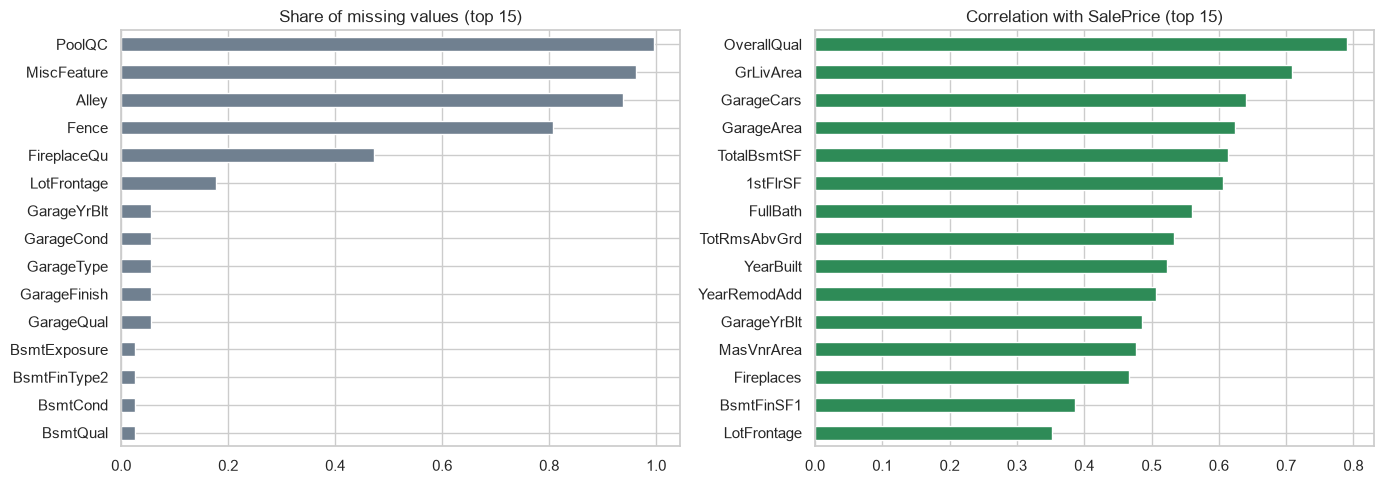

In [5]:
# Missing values and strongest numeric correlations with price
missing = df.isna().mean().sort_values(ascending=False)
missing = missing[missing > 0]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
missing.head(15).plot.barh(ax=axes[0], color="slategray")
axes[0].invert_yaxis(); axes[0].set_title("Share of missing values (top 15)")

corr = df.select_dtypes("number").corr()[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
corr.head(15).plot.barh(ax=axes[1], color="seagreen")
axes[1].invert_yaxis(); axes[1].set_title("Correlation with SalePrice (top 15)")
plt.tight_layout(); plt.show()

## 3. Train/test split and preprocessing

* **Target:** we model `log(1 + SalePrice)`. This is the competition's metric (RMSE on log price) and it stops expensive homes from dominating the error. Predictions are converted back to dollars for reporting.
* **Features:** tree models don't need scaling or one-hot encoding, so numeric columns get median imputation and categorical columns get a `"Missing"` fill plus ordinal encoding. The identical pipeline is used for all three models.

In [6]:
X = df.drop(columns=[TARGET])
y = np.log1p(df[TARGET])

num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
X[cat_cols] = X[cat_cols].astype("object")
print(f"{len(num_cols)} numeric and {len(cat_cols)} categorical features")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print(f"Train: {X_train.shape[0]} homes | Test: {X_test.shape[0]} homes")

preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
        ("encode", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)),
    ]), cat_cols),
])

def make_pipeline(model):
    return Pipeline([("prep", preprocessor), ("model", model)])

36 numeric and 43 categorical features
Train: 1168 homes | Test: 292 homes


## 4. Baseline models (5-fold cross-validation on the training set)

In [7]:
baseline_models = {
    "Decision Tree": DecisionTreeRegressor(random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE),
    "XGBoost": XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=4,
                            subsample=0.8, colsample_bytree=0.8,
                            n_jobs=-1, random_state=RANDOM_STATE),
}

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows, cv_scores = [], {}

for name, model in baseline_models.items():
    res = cross_validate(make_pipeline(model), X_train, y_train, cv=cv,
                         scoring=["neg_root_mean_squared_error", "r2"],
                         return_train_score=True, n_jobs=1)
    rmse = -res["test_neg_root_mean_squared_error"]
    cv_scores[name] = rmse
    cv_rows.append({
        "Model": name,
        "CV RMSE (log)": rmse.mean(),
        "CV RMSE std": rmse.std(),
        "Train RMSE (log)": -res["train_neg_root_mean_squared_error"].mean(),
        "CV R²": res["test_r2"].mean(),
        "Fit time / fold (s)": res["fit_time"].mean(),
    })

cv_df = pd.DataFrame(cv_rows).set_index("Model")
cv_df.style.format("{:.4f}").highlight_min(subset=["CV RMSE (log)"], color="lightgreen")

,CV RMSE (log),CV RMSE std,Train RMSE (log),CV R²,Fit time / fold (s)
Model,,,,,
Decision Tree,0.2070,0.0210,0.0000,0.7164,0.0401
Random Forest,0.1455,0.0149,0.0542,0.8607,0.2796
XGBoost,0.1268,0.0148,0.0249,0.8942,0.4585


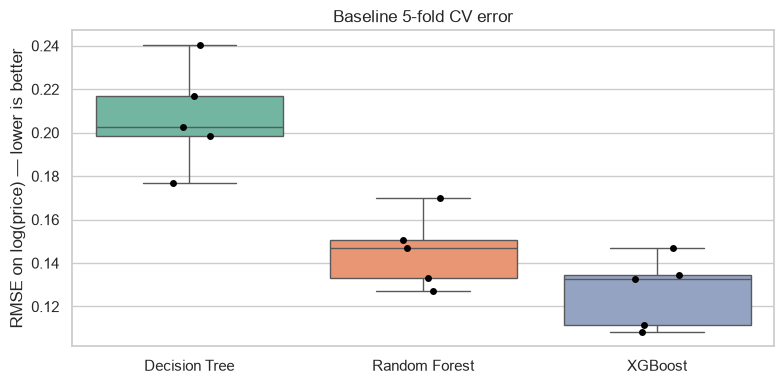

In [8]:
# Fold-by-fold spread: a tight box means a stable model.
# A big gap between Train RMSE and CV RMSE above signals overfitting (look at the single tree).
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=pd.DataFrame(cv_scores), ax=ax, palette="Set2")
sns.stripplot(data=pd.DataFrame(cv_scores), ax=ax, color="black", size=5)
ax.set_ylabel("RMSE on log(price) — lower is better")
ax.set_title("Baseline 5-fold CV error")
plt.tight_layout(); plt.show()

## 5. Hyperparameter tuning (same budget for every model)

Each model gets a `RandomizedSearchCV` with the same number of candidates and folds, so the comparison stays fair. Increase `N_ITER` for a more thorough search.

In [9]:
N_ITER = 25

search_spaces = {
    "Decision Tree": (
        DecisionTreeRegressor(random_state=RANDOM_STATE),
        {
            "model__max_depth": randint(3, 20),
            "model__min_samples_split": randint(2, 40),
            "model__min_samples_leaf": randint(1, 20),
            "model__max_features": [None, "sqrt", 0.5, 0.7],
            "model__ccp_alpha": loguniform(1e-6, 1e-2),
        },
    ),
    "Random Forest": (
        RandomForestRegressor(n_jobs=-1, random_state=RANDOM_STATE),
        {
            "model__n_estimators": randint(200, 700),
            "model__max_depth": [None, 10, 15, 20, 30],
            "model__min_samples_split": randint(2, 10),
            "model__min_samples_leaf": randint(1, 5),
            "model__max_features": ["sqrt", 0.3, 0.5, 0.7],
        },
    ),
    "XGBoost": (
        XGBRegressor(n_jobs=-1, random_state=RANDOM_STATE),
        {
            "model__n_estimators": randint(300, 1500),
            "model__learning_rate": loguniform(0.01, 0.2),
            "model__max_depth": randint(2, 8),
            "model__min_child_weight": randint(1, 10),
            "model__subsample": uniform(0.6, 0.4),
            "model__colsample_bytree": uniform(0.3, 0.7),
            "model__reg_alpha": loguniform(1e-4, 1),
            "model__reg_lambda": loguniform(1e-2, 10),
        },
    ),
}

tuned_models, tuning_rows = {}, []
for name, (model, params) in search_spaces.items():
    start = time.perf_counter()
    search = RandomizedSearchCV(make_pipeline(model), params, n_iter=N_ITER, cv=cv,
                                scoring="neg_root_mean_squared_error",
                                random_state=RANDOM_STATE, n_jobs=-1)
    search.fit(X_train, y_train)
    elapsed = time.perf_counter() - start
    tuned_models[name] = search.best_estimator_
    tuning_rows.append({
        "Model": name,
        "Baseline CV RMSE": cv_df.loc[name, "CV RMSE (log)"],
        "Tuned CV RMSE": -search.best_score_,
        "Search time (s)": elapsed,
    })
    best = {k.replace("model__", ""): (round(v, 4) if isinstance(v, float) else v)
            for k, v in search.best_params_.items()}
    print(f"{name}: best CV RMSE = {-search.best_score_:.4f}  ({elapsed:.0f}s)\n   {best}\n")

tuning_df = pd.DataFrame(tuning_rows).set_index("Model")
tuning_df["Improvement %"] = 100 * (1 - tuning_df["Tuned CV RMSE"] / tuning_df["Baseline CV RMSE"])
tuning_df.style.format("{:.4f}")

Decision Tree: best CV RMSE = 0.1877  (6s)
   {'ccp_alpha': np.float64(0.0), 'max_depth': 17, 'max_features': 0.7, 'min_samples_leaf': 7, 'min_samples_split': 9}



/Users/ndg00008/Documents/profgarrett/jsgames/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/ndg00008/Documents/profgarrett/jsgames/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/Users/ndg00008/Documents/profgarrett/jsgames/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  w

Random Forest: best CV RMSE = 0.1396  (18s)
   {'max_depth': 15, 'max_features': 0.3, 'min_samples_leaf': 1, 'min_samples_split': 3, 'n_estimators': 543}

XGBoost: best CV RMSE = 0.1223  (7s)
   {'colsample_bytree': np.float64(0.336), 'learning_rate': np.float64(0.023), 'max_depth': 2, 'min_child_weight': 1, 'n_estimators': 1453, 'reg_alpha': np.float64(0.0133), 'reg_lambda': np.float64(0.2205), 'subsample': np.float64(0.8212)}



,Baseline CV RMSE,Tuned CV RMSE,Search time (s),Improvement %
Model,,,,
Decision Tree,0.2070,0.1877,5.9330,9.3358
Random Forest,0.1455,0.1396,17.9970,4.0882
XGBoost,0.1268,0.1223,6.9899,3.5356


## 6. Final evaluation on the held-out test set

In [10]:
def evaluate(name, pipe):
    start = time.perf_counter()
    pipe.fit(X_train, y_train)
    fit_time = time.perf_counter() - start

    start = time.perf_counter()
    pred_log = pipe.predict(X_test)
    pred_time = time.perf_counter() - start

    y_true, y_pred = np.expm1(y_test), np.expm1(pred_log)
    return {
        "Model": name,
        "RMSE (log)": np.sqrt(mean_squared_error(y_test, pred_log)),
        "RMSE ($)": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE ($)": mean_absolute_error(y_true, y_pred),
        "MAPE (%)": 100 * np.mean(np.abs((y_true - y_pred) / y_true)),
        "R²": r2_score(y_true, y_pred),
        "Fit time (s)": fit_time,
        "Predict time (ms)": 1000 * pred_time,
    }, y_pred

results, predictions = [], {}
for name, pipe in tuned_models.items():
    row, predictions[name] = evaluate(name, pipe)
    results.append(row)

results_df = pd.DataFrame(results).set_index("Model").sort_values("RMSE (log)")
(results_df.style
    .format({"RMSE (log)": "{:.4f}", "RMSE ($)": "${:,.0f}", "MAE ($)": "${:,.0f}",
             "MAPE (%)": "{:.2f}", "R²": "{:.4f}", "Fit time (s)": "{:.2f}",
             "Predict time (ms)": "{:.1f}"})
    .highlight_min(subset=["RMSE (log)", "RMSE ($)", "MAE ($)", "MAPE (%)"], color="lightgreen")
    .highlight_max(subset=["R²"], color="lightgreen"))

,RMSE (log),RMSE ($),MAE ($),MAPE (%),R²,Fit time (s),Predict time (ms)
Model,,,,,,,
XGBoost,0.1284,"$25,226","$15,589",9.10,0.9170,0.77,5.7
Random Forest,0.1476,"$30,353","$16,824",9.98,0.8799,0.32,44.0
Decision Tree,0.1880,"$38,062","$24,145",13.88,0.8111,0.02,4.6


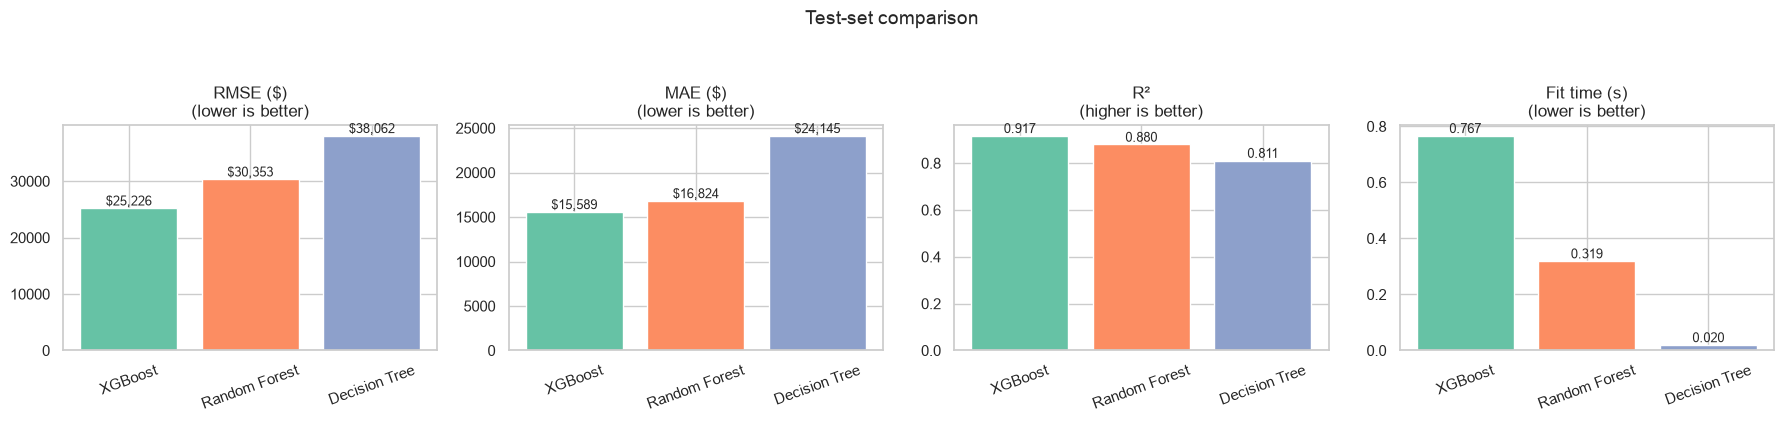

In [11]:
palette = dict(zip(results_df.index, sns.color_palette("Set2", len(results_df))))
metrics = [("RMSE ($)", "lower is better"), ("MAE ($)", "lower is better"),
           ("R²", "higher is better"), ("Fit time (s)", "lower is better")]

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (metric, note) in zip(axes, metrics):
    vals = results_df[metric]
    bars = ax.bar(vals.index, vals, color=[palette[m] for m in vals.index])
    ax.bar_label(bars, fmt="{:,.3f}" if metric in ("R²", "Fit time (s)") else "${:,.0f}", fontsize=9)
    ax.set_title(f"{metric}\n({note})")
    ax.tick_params(axis="x", rotation=20)
plt.suptitle("Test-set comparison", fontsize=14, y=1.05)
plt.tight_layout(); plt.show()

## 7. Predicted vs. actual and residuals

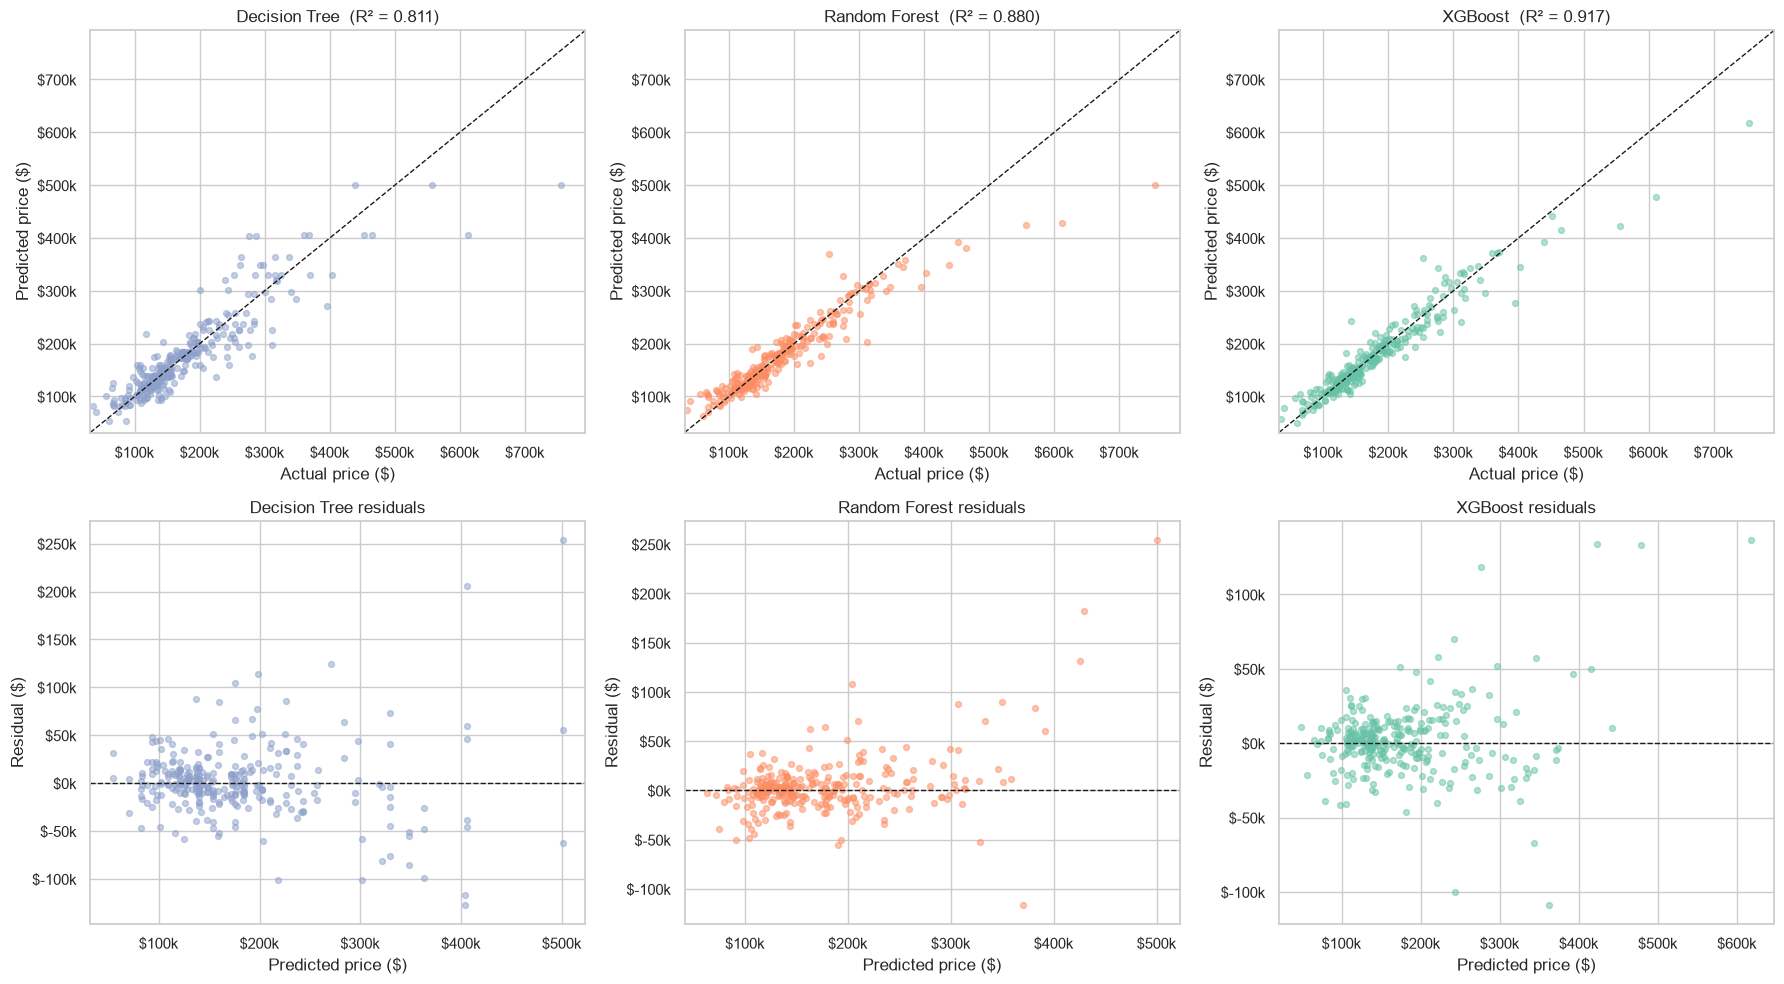

In [12]:
y_true = np.expm1(y_test)
lims = [y_true.min() * 0.9, y_true.max() * 1.05]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for i, (name, y_pred) in enumerate(predictions.items()):
    ax = axes[0, i]
    ax.scatter(y_true, y_pred, alpha=0.5, s=18, color=palette[name])
    ax.plot(lims, lims, "k--", lw=1)
    ax.set(xlim=lims, ylim=lims, xlabel="Actual price ($)", ylabel="Predicted price ($)",
           title=f"{name}  (R² = {r2_score(y_true, y_pred):.3f})")

    ax = axes[1, i]
    resid = y_true - y_pred
    ax.scatter(y_pred, resid, alpha=0.5, s=18, color=palette[name])
    ax.axhline(0, color="k", ls="--", lw=1)
    ax.set(xlabel="Predicted price ($)", ylabel="Residual ($)", title=f"{name} residuals")
for ax in axes.flat:
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v/1000:.0f}k"))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v/1000:.0f}k"))
plt.tight_layout(); plt.show()

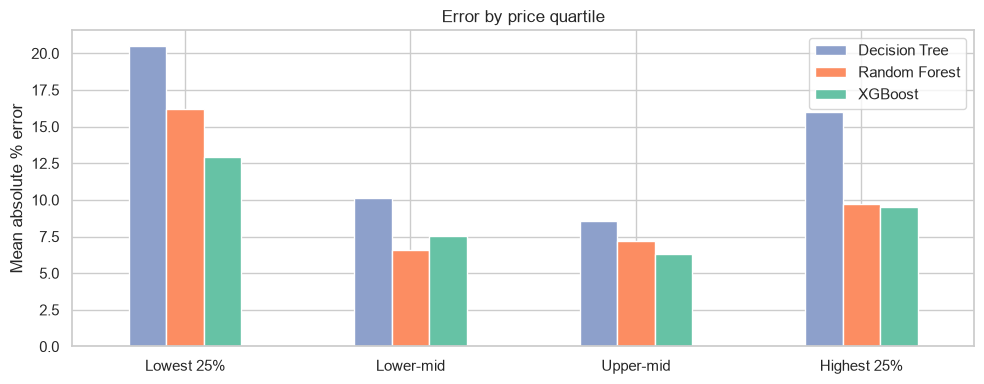

In [13]:
# Error by price band: where does each model struggle?
bands = pd.qcut(y_true, 4, labels=["Lowest 25%", "Lower-mid", "Upper-mid", "Highest 25%"])
band_err = pd.DataFrame({
    name: pd.Series(np.abs(y_true - pred) / y_true * 100).groupby(bands.values).mean()
    for name, pred in predictions.items()
})
ax = band_err.plot.bar(figsize=(10, 4), color=[palette[m] for m in band_err.columns], rot=0)
ax.set_ylabel("Mean absolute % error"); ax.set_title("Error by price quartile")
plt.tight_layout(); plt.show()

## 8. Feature importances

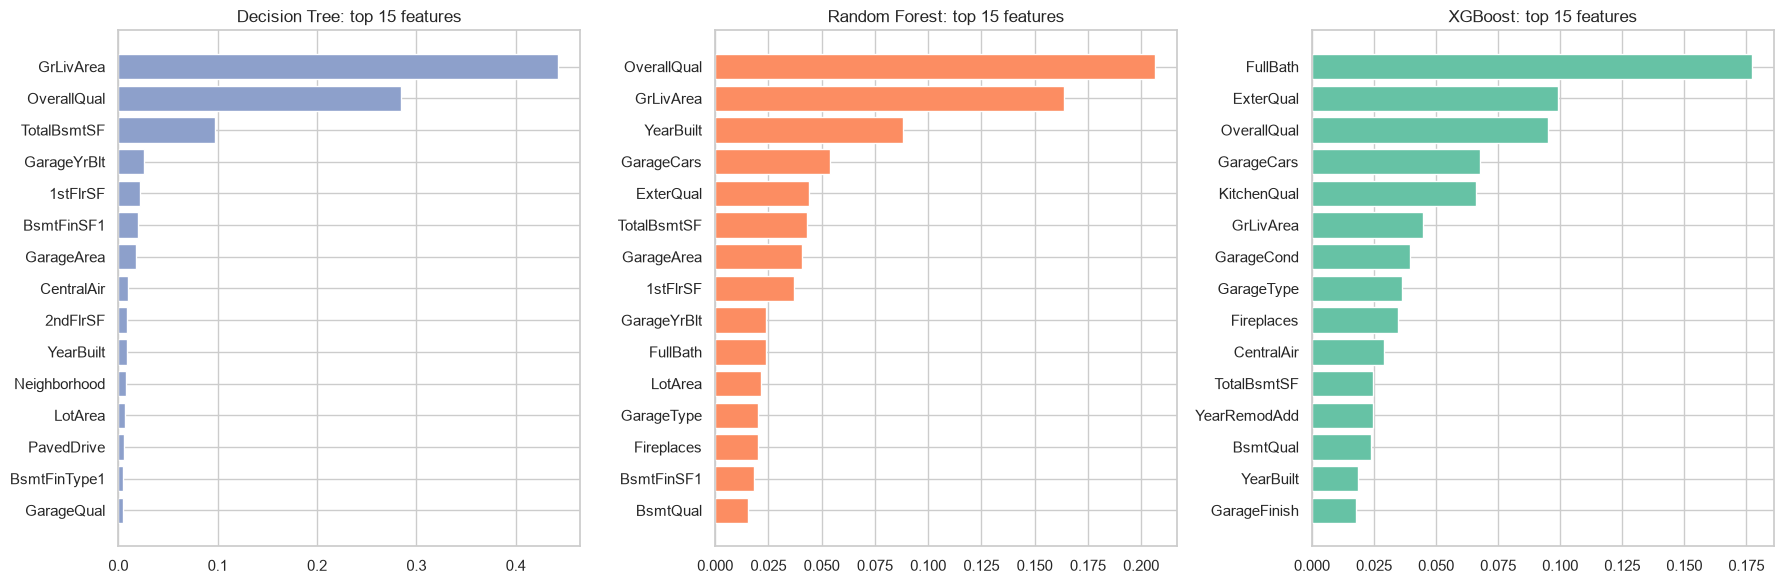

Spearman rank correlation of feature importances:


,Decision Tree,Random Forest,XGBoost
Decision Tree,1.0,0.70,0.50
Random Forest,0.7,1.00,0.72
XGBoost,0.5,0.72,1.00


In [14]:
feature_names = num_cols + cat_cols

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
importance_table = {}
for ax, (name, pipe) in zip(axes, tuned_models.items()):
    imp = pd.Series(pipe.named_steps["model"].feature_importances_, index=feature_names)
    importance_table[name] = imp
    top = imp.sort_values(ascending=False).head(15)
    ax.barh(top.index[::-1], top.values[::-1], color=palette[name])
    ax.set_title(f"{name}: top 15 features")
plt.tight_layout(); plt.show()

# How much do the models agree on what matters?
imp_df = pd.DataFrame(importance_table)
print("Spearman rank correlation of feature importances:")
imp_df.corr(method="spearman").round(2)

## 9. Takeaways

Run the notebook and compare the tables above. Typical findings on this dataset:

* **Decision Tree** has the largest error and the biggest train-vs-CV gap: a single tree memorizes the training data. Tuning (limiting depth, leaf size, pruning) helps, but it remains the weakest model. Its advantage is interpretability and speed.
* **Random Forest** cuts the error substantially by averaging many decorrelated trees, and works well with little tuning.
* **XGBoost** is usually the most accurate (lowest RMSE / highest R²) because boosting reduces bias as well as variance, but it has the most hyperparameters and benefits most from tuning.
* All three agree that overall quality (`OverallQual`), living area (`GrLivArea`), basement and garage size, and year built are top drivers of price.
* Most of the error comes from the most expensive homes — consider the price-quartile chart before trusting any single model on luxury properties.

**Ideas to extend:** engineer features (total square footage, house age, total bathrooms), remove the few known outliers (very large homes sold cheaply), try LightGBM/CatBoost, or stack the Random Forest and XGBoost predictions.